In [71]:
import gzip
import os
import struct
import time
import urllib.request

import numpy as np
import matplotlib.pyplot as plt

SEED = 777
np.random.seed(SEED)
print("NumPy", np.__version__)

NumPy 2.1.3


In [72]:
DATA_DIR = "mnist"

MNIST_FILES = {
    "train_images": "train-images-idx3-ubyte",
    "train_labels": "train-labels-idx1-ubyte",
    "test_images":  "t10k-images-idx3-ubyte",
    "test_labels":  "t10k-labels-idx1-ubyte",
}
MIRRORS = [
    "https://raw.githubusercontent.com/fgnt/mnist/master/",
    "https://storage.googleapis.com/cvdf-datasets/mnist/",
    "https://ossci-datasets.s3.amazonaws.com/mnist/",
]


def _normalize(name):
    name = name.lower()
    if name.endswith(".gz"):
        name = name[:-3]
    return name.replace(".", "-")


def find_or_download_mnist(data_dir):
    paths = {}
    if os.path.isdir(data_dir):
        for root, _, files in os.walk(data_dir):
            for fname in files:
                norm = _normalize(fname)
                for key, base in MNIST_FILES.items():
                    if norm == base and key not in paths:
                        paths[key] = os.path.join(root, fname)
    missing = [k for k in MNIST_FILES if k not in paths]
    if missing:
        os.makedirs(data_dir, exist_ok=True)
        for key in missing:
            fname = MNIST_FILES[key] + ".gz"
            dst = os.path.join(data_dir, fname)
            for mirror in MIRRORS:
                try:
                    print("Скачивание", mirror + fname)
                    urllib.request.urlretrieve(mirror + fname, dst)
                    paths[key] = dst
                    break
                except Exception as e:
                    print("  не удалось:", e)
            if key not in paths:
                raise FileNotFoundError(
                    f"Не найден файл {MNIST_FILES[key]}: положите MNIST в папку '{data_dir}'")
    return paths


def read_idx(path):
    opener = gzip.open if path.endswith(".gz") else open
    with opener(path, "rb") as f:
        magic = struct.unpack(">I", f.read(4))[0]
        ndim = magic & 0xFF
        shape = struct.unpack(">" + "I" * ndim, f.read(4 * ndim))
        data = np.frombuffer(f.read(), dtype=np.uint8)
    return data.reshape(shape)


paths = find_or_download_mnist(DATA_DIR)
for k, p in paths.items():
    print(f"{k:13s} <- {p}")

train_images_raw = read_idx(paths["train_images"])
train_labels_raw = read_idx(paths["train_labels"])
test_images_raw  = read_idx(paths["test_images"])
test_labels_raw  = read_idx(paths["test_labels"])

test_images   <- mnist\t10k-images-idx3-ubyte.gz
test_labels   <- mnist\t10k-labels-idx1-ubyte.gz
train_images  <- mnist\train-images-idx3-ubyte.gz
train_labels  <- mnist\train-labels-idx1-ubyte.gz


In [73]:
print(f"Тренировочная выборка: {train_images_raw.shape[0]} изображений, {train_labels_raw.shape[0]} меток")
print(f"Тестовая выборка:      {test_images_raw.shape[0]} изображений, {test_labels_raw.shape[0]} меток")
print(f"Форма одного изображения: {train_images_raw[0].shape}")

Тренировочная выборка: 60000 изображений, 60000 меток
Тестовая выборка:      10000 изображений, 10000 меток
Форма одного изображения: (28, 28)


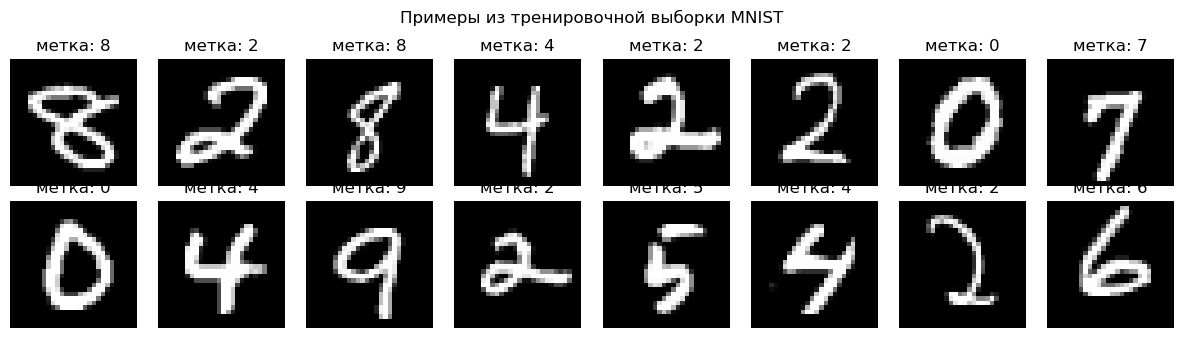

In [74]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
idx = np.random.default_rng(0).choice(len(train_images_raw), size=16, replace=False)
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(train_images_raw[i], cmap="gray")
    ax.set_title(f"метка: {train_labels_raw[i]}")
    ax.axis("off")
plt.suptitle("Примеры из тренировочной выборки MNIST")
plt.tight_layout()
plt.show()

In [75]:
def preprocess_images(images):
    return images.reshape(images.shape[0], -1).astype(np.float32) / 255.0


def one_hot(labels, num_classes=10):
    y = np.zeros((labels.shape[0], num_classes), dtype=np.float32)
    y[np.arange(labels.shape[0]), labels] = 1.0
    return y


X_train, X_test = preprocess_images(train_images_raw), preprocess_images(test_images_raw)
y_train, y_test = train_labels_raw.astype(np.int64), test_labels_raw.astype(np.int64)
Y_train, Y_test = one_hot(y_train), one_hot(y_test)

print("X_train:", X_train.shape)
print("Y_train:", Y_train.shape)
print("X_test: ", X_test.shape)
print("Y_test: ", Y_test.shape)
print("Метка", y_train[0], "-> one-hot", Y_train[0])

X_train: (60000, 784)
Y_train: (60000, 10)
X_test:  (10000, 784)
Y_test:  (10000, 10)
Метка 5 -> one-hot [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


In [76]:
def relu(z):
    return np.maximum(z, 0)


def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def cross_entropy(U, Y, eps=1e-12):
    return float(-np.sum(Y * np.log(U + eps)) / U.shape[0])


class TwoLayerNet:

    def __init__(self, n_input, n_hidden, n_output, seed=SEED):
        rng = np.random.default_rng(seed)
        self.W1 = rng.normal(0.0, np.sqrt(2.0 / n_input), (n_input, n_hidden)).astype(np.float32)
        a = np.sqrt(6.0 / (n_hidden + n_output))
        self.W2 = rng.uniform(-a, a, (n_hidden, n_output)).astype(np.float32)
        self.b1 = np.zeros(n_hidden, dtype=np.float32)
        self.b2 = np.zeros(n_output, dtype=np.float32)

    def forward(self, X):
        F = X @ self.W1 + self.b1
        V = relu(F)
        G = V @ self.W2 + self.b2
        U = softmax(G)
        self.cache = (X, F, V)
        return U

    def backward(self, U, Y):
        X, F, V = self.cache
        B = X.shape[0]
        D2 = (U - Y) / B
        dW2 = V.T @ D2
        db2 = D2.sum(axis=0)
        D1 = (D2 @ self.W2.T) * (F > 0)
        dW1 = X.T @ D1
        db1 = D1.sum(axis=0)
        return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}

    def step(self, grads, lr):
        self.W1 -= lr * grads["W1"]
        self.b1 -= lr * grads["b1"]
        self.W2 -= lr * grads["W2"]
        self.b2 -= lr * grads["b2"]

    def predict_proba(self, X, batch_size=10000):
        out = [softmax(relu(X[i:i + batch_size] @ self.W1 + self.b1) @ self.W2 + self.b2)
               for i in range(0, X.shape[0], batch_size)]
        return np.concatenate(out)

    def evaluate(self, X, Y):
        U = self.predict_proba(X)
        acc = float(np.mean(U.argmax(axis=1) == Y.argmax(axis=1)))
        return cross_entropy(U, Y), acc, 1.0 - acc

In [77]:
def gradient_check(n_checks=20, eps=1e-5, seed=0):
    rng = np.random.default_rng(seed)
    net = TwoLayerNet(784, 16, 10, seed=seed)
    for name in ("W1", "b1", "W2", "b2"):
        setattr(net, name, getattr(net, name).astype(np.float64) + 0.1 * rng.standard_normal(getattr(net, name).shape))
    Xb, Yb = X_train[:8].astype(np.float64), Y_train[:8].astype(np.float64)

    grads = net.backward(net.forward(Xb), Yb)
    for name in ("W1", "b1", "W2", "b2"):
        param = getattr(net, name)
        max_rel = 0.0
        for _ in range(n_checks):
            ix = tuple(rng.integers(0, d) for d in param.shape)
            old = param[ix]
            param[ix] = old + eps; e_plus = cross_entropy(net.forward(Xb), Yb, eps=0)
            param[ix] = old - eps; e_minus = cross_entropy(net.forward(Xb), Yb, eps=0)
            param[ix] = old
            num = (e_plus - e_minus) / (2 * eps)
            ana = grads[name][ix]
            max_rel = max(max_rel, abs(num - ana) / max(1e-12, abs(num) + abs(ana)))
        print(f"{name}: максимальная относительная ошибка = {max_rel:.2e}")


gradient_check()

W1: максимальная относительная ошибка = 7.88e-10
b1: максимальная относительная ошибка = 9.08e-10
W2: максимальная относительная ошибка = 2.49e-08
b2: максимальная относительная ошибка = 1.68e-10


In [78]:
def train(net, X, Y, lr=0.1, batch_size=32, epochs=20, seed=SEED, verbose=True):
    rng = np.random.default_rng(seed)
    n = X.shape[0]
    history = {"loss": [], "error": [], "time": []}
    for epoch in range(1, epochs + 1):
        t0 = time.perf_counter()
        perm = rng.permutation(n)
        for start in range(0, n, batch_size):
            idx = perm[start:start + batch_size]
            Xb, Yb = X[idx], Y[idx]
            U = net.forward(Xb)
            grads = net.backward(U, Yb)
            net.step(grads, lr)
        epoch_time = time.perf_counter() - t0

        loss, acc, err = net.evaluate(X, Y)
        history["loss"].append(loss); history["error"].append(err); history["time"].append(epoch_time)
        if verbose:
            print(f"Эпоха {epoch:2d}/{epochs}: train loss = {loss:.4f}, "
                  f"train ошибка = {err * 100:5.2f}% (точность {acc * 100:5.2f}%), время = {epoch_time:.2f} с")
    return history

In [79]:
BATCH_SIZE = 32
LEARNING_RATE = 0.1
HIDDEN = 300
EPOCHS = 20

net = TwoLayerNet(n_input=X_train.shape[1], n_hidden=HIDDEN, n_output=10)

t_start = time.perf_counter()
history = train(net, X_train, Y_train, lr=LEARNING_RATE, batch_size=BATCH_SIZE, epochs=EPOCHS)
total_time = time.perf_counter() - t_start
print(f"\nОбщее время обучения: {total_time:.1f} с ({total_time / 60:.1f} мин)")

Эпоха  1/20: train loss = 0.1647, train ошибка =  4.74% (точность 95.26%), время = 0.99 с
Эпоха  2/20: train loss = 0.0954, train ошибка =  2.67% (точность 97.33%), время = 1.10 с
Эпоха  3/20: train loss = 0.0717, train ошибка =  2.04% (точность 97.96%), время = 1.08 с
Эпоха  4/20: train loss = 0.0572, train ошибка =  1.54% (точность 98.46%), время = 1.06 с
Эпоха  5/20: train loss = 0.0464, train ошибка =  1.21% (точность 98.79%), время = 1.07 с
Эпоха  6/20: train loss = 0.0380, train ошибка =  0.99% (точность 99.01%), время = 0.93 с
Эпоха  7/20: train loss = 0.0320, train ошибка =  0.76% (точность 99.24%), время = 0.70 с
Эпоха  8/20: train loss = 0.0253, train ошибка =  0.60% (точность 99.40%), время = 0.74 с
Эпоха  9/20: train loss = 0.0217, train ошибка =  0.44% (точность 99.56%), время = 1.13 с
Эпоха 10/20: train loss = 0.0180, train ошибка =  0.35% (точность 99.65%), время = 0.92 с
Эпоха 11/20: train loss = 0.0165, train ошибка =  0.31% (точность 99.69%), время = 0.73 с
Эпоха 12/2

In [80]:
test_loss, test_acc, test_err = net.evaluate(X_test, Y_test)
print(f"Тестовая выборка ({X_test.shape[0]} изображений):")
print(f"  кросс-энтропия        = {test_loss:.4f}")
print(f"  ошибка классификации  = {test_err * 100:.2f}%")
print(f"  точность              = {test_acc * 100:.2f}%")

Тестовая выборка (10000 изображений):
  кросс-энтропия        = 0.0590
  ошибка классификации  = 1.80%
  точность              = 98.20%


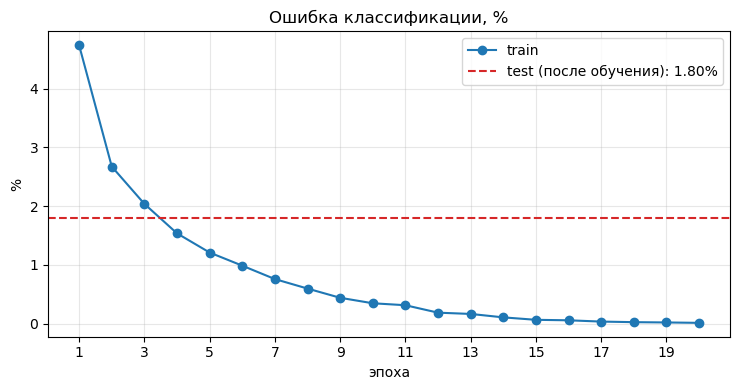

In [81]:
epochs_axis = np.arange(1, EPOCHS + 1)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(epochs_axis, np.array(history["error"]) * 100, marker="o", label="train")
ax.axhline(test_err * 100, color="tab:red", linestyle="--", label=f"test (после обучения): {test_err * 100:.2f}%")
ax.set_title("Ошибка классификации, %")
ax.set_xlabel("эпоха")
ax.set_ylabel("%")
ax.set_xticks(epochs_axis[::2] if EPOCHS > 10 else epochs_axis)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

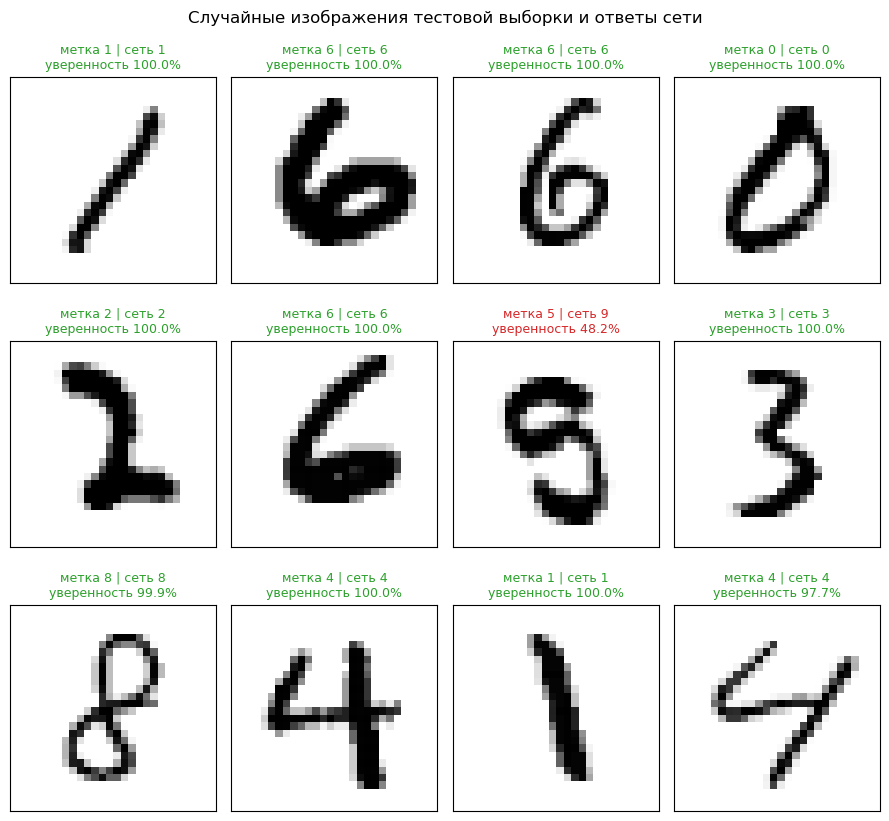

In [82]:
probs_test = net.predict_proba(X_test)
pred_labels = probs_test.argmax(axis=1)
sample = np.random.default_rng(SEED).choice(len(X_test), size=12, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(9, 8.6))
for ax, k in zip(axes.ravel(), sample):
    ok = pred_labels[k] == y_test[k]
    ax.imshow(test_images_raw[k], cmap="binary")
    ax.set_title(
        f"метка {y_test[k]} | сеть {pred_labels[k]}\n"
        f"уверенность {probs_test[k, pred_labels[k]]:.1%}",
        color="tab:green" if ok else "tab:red",
        fontsize=9,
    )
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Случайные изображения тестовой выборки и ответы сети")
plt.tight_layout()
plt.show()